## Why start with MNIST

DP-SGD protects every training example the same way. It caps how far any one example can push the model (**clipping**), then blurs each update with random **noise**. The guarantee holds *per record*. Our question is whether the *accuracy cost* is shared evenly, or whether some groups pay more.

On MNIST we can make a group rare on purpose. We keep only about 1% of the training images of the digit **8** and leave every other digit intact. That way we know exactly what makes 8 different: it has far fewer training examples. Digit **2** is the control. This is a mechanism demonstration. MNIST has no people in it, so it supports no conclusions about fairness to people. The [Adult page](02_adult_subgroup_disparity.ipynb) covers that.

## Setup

- **Data:** each training 8 is kept with probability 0.09, which leaves 513–537 eights per seed (about 1% of the training data). All 5,958 twos are kept. We evaluate on the full 10,000-image test set (974 eights, 1,032 twos).
- **Model:** two 3×3 conv layers (32 and 16 channels), tanh, no pooling, then a linear layer to 10 classes (97,114 parameters).
- **Training:** cross-entropy, plain SGD (no momentum), 60 epochs, batch size 256. Private runs use Poisson sampling and an RDP accountant with $\delta = 10^{-6}$.
- **Seeds:** five (0–4). Within a seed, every method sees the same training subset and starts from the same initial weights.
- **Methods**, following the proposal's four-phase design:
  1. non-private baseline;
  2. standard DP-SGD;
  3. disparity evaluation (no training);
  4. DPSGD-Global-Adapt.

The hyperparameters follow Esipova et al. (2023), App. B:

In [1]:
import pandas as pd
from dpdisparity import analysis as A, plots, runner

SOURCE = "legacy"  # "legacy" = frozen dp-testing runs; "rerun" = train any missing runs with this repo's pipeline

In [2]:
#| label: tbl-mnist-settings
#| tbl-cap: "Hyperparameters per method (Esipova et al., App. B)."
A.settings_table("mnist")

,epochs,lr,batch_size,σ,C,Z₀,τ,σ₂,η_Z,δ
Non-private,60,0.01,256,,,,,,,1e-06
DP-SGD,60,0.01,256,0.8,1.0,,,,,1e-06
Global-Adapt,60,0.1,256,0.8,1.0,50.0,0.7,10.0,0.1,1e-06


In [3]:
results = runner.load("mnist", SOURCE)
df = A.to_frame(results)
acc = A.summarize(df, "accuracy")
DIGITS = [str(d) for d in range(10)]

## Phase 1: Non-private baseline

Even without privacy, the rare digit is harder. Trained on about 530 examples instead of about 6,000, the model gets roughly 86% of test 8s right, against about 98% of 2s. This gap exists *before* any privacy is added. That is why we measure the **privacy cost** (how much accuracy each group *loses* when privacy is switched on) and not the raw accuracy gap.

In [4]:
#| label: tbl-mnist-phase1
#| tbl-cap: "Non-private test accuracy (%), mean ± SE over 5 seeds (ours)."
acc[(acc.method == "nonprivate") & acc.group.isin(["2", "8"])].round(2)

,method,group,mean,sd,n,se
2,nonprivate,2,97.73,0.22,5,0.10
8,nonprivate,8,86.32,1.37,5,0.61


## Phase 2: DP-SGD

With DP-SGD ($C = 1$, $\sigma = 0.8$, $\varepsilon \approx 5.9$), every digit loses some accuracy, but the rare 8 collapses. Its accuracy falls from about 86% to about 25%, while the 2 drops by only about 9 points.

The leading explanation is **gradient misalignment** (Esipova et al., 2023):

- Examples the model fits badly, such as the rare 8s, produce large gradients, so clipping shrinks them the most.
- Clipping therefore changes the **direction** of each update, not just its size, and pulls it toward the well-fit majority.
- The noise is random and largely averages out over training. The clipping bias is systematic and accumulates.

The outcome numbers here are *consistent with* that explanation. They do not test it; the planned mechanism experiments do.

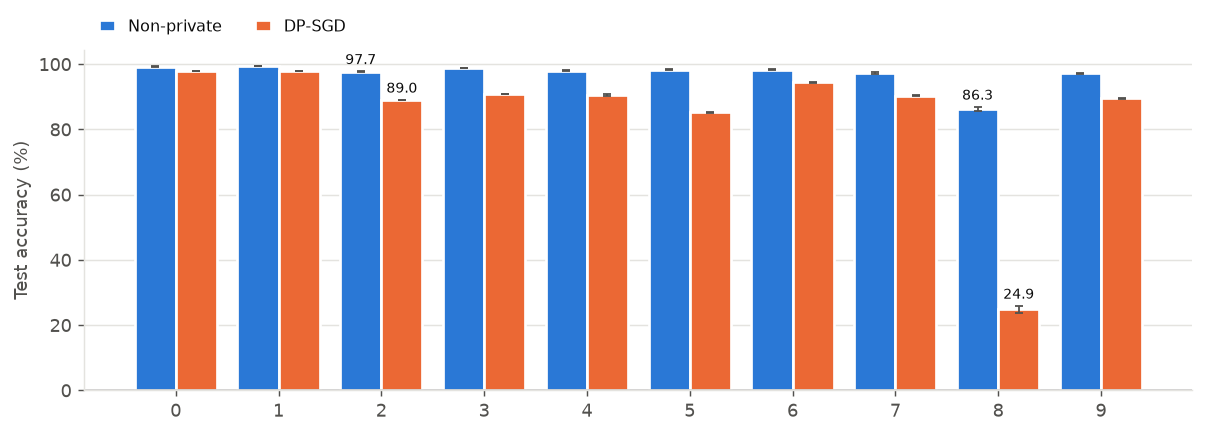

In [5]:
#| label: fig-mnist-dpsgd
#| fig-cap: "Per-digit test accuracy, non-private vs DP-SGD (ours; mean ± SE over 5 seeds)."
plots.group_bars(acc[acc.method != "global_adapt"], DIGITS, "Test accuracy (%)", label_groups=("2", "8"));

## Phase 3: Disparity evaluation

For each digit $k$, the privacy cost is $\pi_k = A_k(\text{non-private}) - A_k(\text{private})$, paired by seed. The disparity measure is the **privacy-cost gap** $\lvert \pi_2 - \pi_8 \rvert$.

The privacy-cost gap is not the raw accuracy gap. Under DP-SGD the raw gap between 2 and 8 is about 64 points, but about 11 of those were already there without privacy. The privacy-cost gap removes that pre-existing difference.

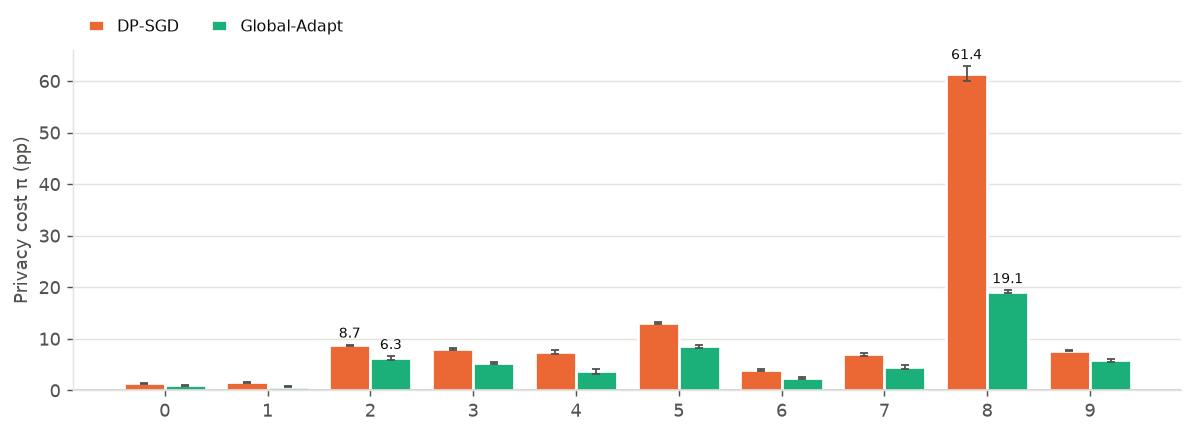

In [6]:
#| label: fig-mnist-cost
#| fig-cap: "Privacy cost per digit (ours; percentage points lost relative to the non-private model)."
costs = A.summarize(A.privacy_costs(df), "pi")
plots.group_bars(costs, DIGITS, "Privacy cost π (pp)", label_groups=("2", "8"));

Under DP-SGD, the 8 loses about **61 points** and the 2 loses about **9**. That is a privacy-cost gap of about **53 points**.

## Phase 4: DPSGD-Global-Adapt

Global-Adapt changes one thing about clipping:

- **DP-SGD** clips each large gradient down to $C$ separately. Big gradients shrink a lot, small ones not at all.
- **Global-Adapt** scales *every* gradient by the same factor $C/Z$, where $Z$ is an upper bound on gradient norms. Their relative sizes, and so the update's direction, are preserved. Only gradients above $Z$ are still clipped.
- **$Z$ is learned privately.** Each step releases a noisy count of how many gradients exceed $\tau \cdot Z$ and adjusts $Z$ from it. That count is charged to the privacy budget ($\varepsilon \approx 5.91$ vs 5.90).
- **No group labels are used.**

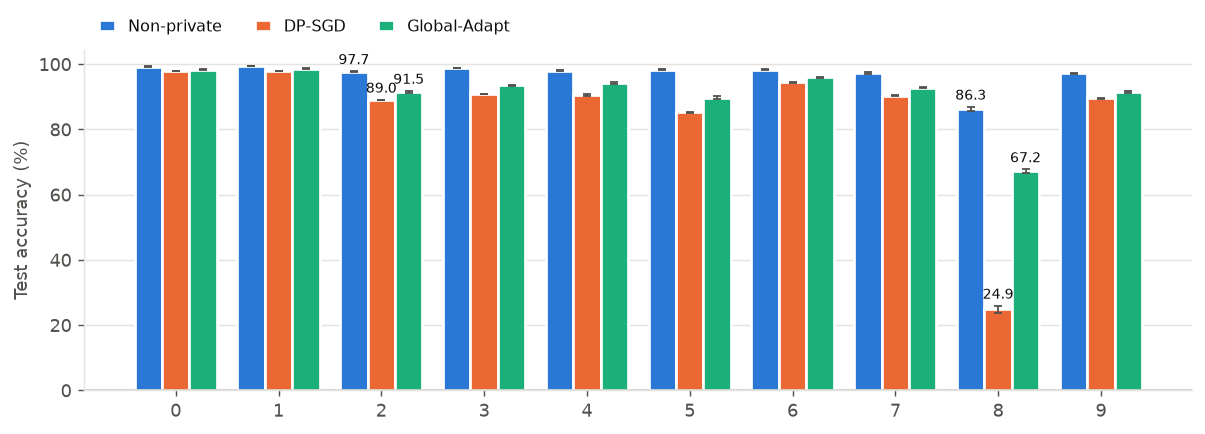

In [7]:
#| label: fig-mnist-acc
#| fig-cap: "Per-digit test accuracy for all three methods (ours; mean ± SE over 5 seeds)."
plots.group_bars(acc, DIGITS, "Test accuracy (%)", label_groups=("2", "8"));

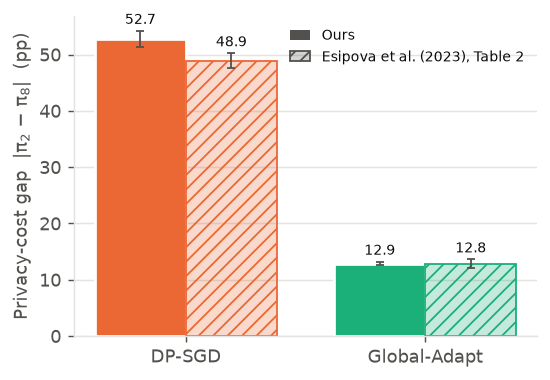

In [8]:
#| label: fig-mnist-gap
#| fig-cap: "Privacy-cost gap $\\lvert \\pi_2 - \\pi_8 \\rvert$: ours vs Esipova et al. (2023), Table 2. Mean ± SE over 5 seeds."
gaps = A.gaps(df, "mnist")
plots.gap_bars(gaps, "mnist");

Global-Adapt lifts the 8 from about 25% to about 67% and shrinks the privacy-cost gap from about 53 to about 13 points. It **reduces** the gap but does not close it. One explanation from the literature is that part of the gap is fundamental: any DP algorithm struggles to learn rare examples (Sanyal et al., 2022). Only the part caused by clipping is fixable this way.

## Comparison with the paper

Every value below is mean ± standard error over 5 seeds, in percentage points. "Ours" rows are our runs. The other rows are Esipova et al.'s published numbers.

In [9]:
#| label: tbl-mnist-compare
#| tbl-cap: "Ours vs Esipova et al. (2023), Table 2. Mean ± SE over 5 seeds."
A.comparison_table(results, "mnist")

Acc 2       Acc 8  \
Method       Source                                                   
Non-private  Ours                            97.7 ± 0.1  86.3 ± 0.6   
             Esipova et al. (2023), Table 2  98.0 ± 0.1  84.3 ± 1.1   
DP-SGD       Ours                            89.0 ± 0.1  24.9 ± 1.0   
             Esipova et al. (2023), Table 2  89.0 ± 0.1  26.3 ± 0.4   
Global-Adapt Ours                            91.5 ± 0.3  67.2 ± 0.6   
             Esipova et al. (2023), Table 2  92.0 ± 0.2  65.5 ± 1.2   

                                                   π 2         π 8  \
Method       Source                                                  
Non-private  Ours                                    –           –   
             Esipova et al. (2023), Table 2          –           –   
DP-SGD       Ours                            8.7 ± 0.1  61.4 ± 1.4   
             Esipova et al. (2023), Table 2  8.9 ± 0.1  57.9 ± 1.3   
Global-Adapt Ours                            6.3 ± 0.4  19.1 ± 0.3   
             Esipova et al. (2023), Table 2  6.0 ± 0.2  18.8 ± 0.9   

                                                     Gap π 2,8     ε  
Method       Source                                                   
Non-private  Ours                            0 (by definition)     –  
             Esipova et al. (2023), Table 2  0 (by definition)     –  
DP-SGD       Ours                                   52.7 ± 1.4  5.90  
             Esipova et al. (2023), Table 2         48.9 ± 1.3     –  
Global-Adapt Ours                                   12.9 ± 0.3  5.91  
             Esipova et al. (2023), Table 2         12.8 ± 0.8     –

Our results **closely track** the paper.

- **Close matches:** every accuracy is within about 2 points of the paper. Global-Adapt's privacy costs and gap are within about 0.5 points.
- **The exception:** our DP-SGD gap (about 52.7 ± 1.4) is about 4 points, roughly 3 standard errors, above the paper's 48.9 ± 1.3. Two differences add up to it:
  - our non-private model is slightly better on 8 (86.3 vs 84.3);
  - our DP-SGD model is slightly worse on 8 (24.9 vs 26.3).
- **Model size:** our CNN has 97,114 parameters, matching the authors' released configuration. The paper's appendix lists 80,522.

## Reproducibility check: rerunning in this repository

The numbers above come from the original `dp-testing` runs. All of MNIST was retrained here with this repository's ported pipeline (`uv run python scripts/sweep.py --dataset mnist`), on an RTX 5060 Ti GPU and with newer library versions. Exact agreement is not expected, because GPU vs CPU and different library versions change the random noise draws. Close agreement shows the port behaves the same.

In [10]:
#| label: tbl-mnist-rerun
#| tbl-cap: "Key numbers (means over 5 seeds): original dp-testing runs vs this repository's rerun."
pd.DataFrame({"dp-testing": A.headline(runner.load("mnist", "legacy"), "mnist"),
              "this repo (rerun)": A.headline(runner.load("mnist", "rerun"), "mnist")})

,dp-testing,this repo (rerun)
Non-private: Acc 2,97.73,98.02
Non-private: Acc 8,86.32,86.43
DP-SGD: Acc 2,89.03,89.09
DP-SGD: Acc 8,24.89,25.09
Global-Adapt: Acc 2,91.47,91.84
Global-Adapt: Acc 8,67.21,67.10
DP-SGD: gap,52.74,52.40
Global-Adapt: gap,12.86,13.14
DP-SGD: ε,5.90,5.90
Global-Adapt: ε,5.91,5.91


The rerun **closely tracks** the original runs (both ours):

- **Accuracies:** every accuracy for digits 2 and 8 is within about 0.4 points.
- **DP-SGD gap:** 52.4 ± 0.5 in the rerun vs 52.7 ± 1.4 in dp-testing.
- **Global-Adapt gap:** 13.1 ± 1.3 vs 12.9 ± 0.3.
- **$\varepsilon$:** unchanged at 5.90 (DP-SGD) and 5.91 (Global-Adapt). MNIST has 214 batches per epoch and Opacus takes 214 steps, so the off-by-one in $\varepsilon$ seen on Adult does not arise here.

**The DP-SGD gap stays above the paper's 48.9 ± 1.3 in the rerun.** The difference from Esipova et al. is therefore not an artefact of the original dp-testing code.

## Run details

In [11]:
#| label: tbl-mnist-runs
#| tbl-cap: "Achieved privacy (RDP accountant) and final $Z$, means over seeds."
A.run_info(results)

,seeds,epsilon,delta,final_Z,source
method,,,,,
Non-private,5,–,–,–,dp-testing
DP-SGD,5,5.903,1e-06,–,dp-testing
Global-Adapt,5,5.909,1e-06,38.49,dp-testing


In [12]:
results[-1]["provenance"]

{'python': '3.13.1',
 'torch': '2.6.0+cu124',
 'torchvision': '0.21.0+cu124',
 'opacus': '1.6.0',
 'device': 'cuda'}

## Takeaways

- **The rare class pays far more.** DP-SGD costs the rare 8 about 61 points of accuracy and the well-represented 2 about 9.
- **Global-Adapt shrinks the gap** from about 53 to about 13 points without using group labels. It does not eliminate it.
- **Cause, so far:** these outcome results are consistent with gradient misalignment. Testing that mechanism directly is the planned next step: per-group clipping rates and gradient angles, and the paper's direction-vs-magnitude experiment.